<h1>CME538 - Introduction to Data Science</h1>
<h2>Lecture 3.1 - Exploratory Data Analysis</h2>
<p>Why this notebook? You will inspect passenger records, aggregate bicycle detections, compare traffic patterns, map housing values, and interpret earthquake magnitudes. Use these checks to judge the evidence before fitting a model.</p>
<p>Central question: Which features of the data support an analysis, and which limit the conclusions?</p>
<p>You will identify the unit in each row, explain the detail lost through aggregation, and distinguish complete timestamps from complete measurements. You will also check the people, places, and periods each dataset covers.</p>
<h3>Lecture Structure</h3>
<ol>
<li><a href="#section1">Structure</a></li>
<li><a href="#section2">Granularity</a></li>
<li><a href="#section3">Temporality</a></li>
<li><a href="#section4">Faithfulness</a></li>
<li><a href="#section5">Scope</a></li>
<li><a href="#section6">Spatiality</a></li>
<li><a href="#section7">Domain Context</a></li>
</ol>
<h3>Lecture slides and data sources</h3>
<p><a href="../slides/week3_lecture1.pptx">Lecture slides</a></p>
<p>The local <code>titanic.csv</code> contains the 891-row teaching extract from the <a href="https://www.kaggle.com/c/titanic/data">Kaggle Titanic competition</a>.</p>
<p><a href="https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k">Seattle Fremont Bridge bicycle-counter data</a>: <code>bike_traffic_data.csv</code> contains the course's historical hourly snapshot. <code>counter_events.csv</code> illustrates individual detections. The hourly sidewalk totals match a two-hour slice of the published data. The event timestamps are illustrative, not sensor measurements or a vendor export.</p>
<p><a href="https://gml.noaa.gov/ccgg/trends/data.html">NOAA Mauna Loa CO₂ data</a>: <code>co2_mm_mlo.txt</code> contains the September 2019 snapshot. The file header documents missing-value codes, interpolation, attribution, and data-use conditions. The header credits early observations to Scripps Institution of Oceanography.</p>
<p><a href="https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset">California housing data</a>: <code>california_housing.csv</code> preserves the 20,640 rows in the StatLib archive distributed by scikit-learn. The file has no header. The selected columns are longitude, latitude, and median home value in 1990 US dollars.</p>
<p><a href="https://earthquake.usgs.gov/earthquakes/search/">USGS earthquake catalogue</a>: <code>usgs_california_nevada_2025_01.csv</code> preserves the January 2025 regional query. The notebook selects reviewed local magnitudes. See the <a href="https://www.usgs.gov/programs/earthquake-hazards/magnitude-types">USGS magnitude definitions</a> and <a href="dataset_sources.md">local dataset details</a>.</p>

<h2>Setup Notebook</h2>
<p>All examples use local files. <code>utils.py</code> handles display settings and figure formatting. The notebook shows the loading, grouping, aggregation, and cleaning decisions.</p>

In [1]:
import numpy as np
import pandas as pd
import utils

RANDOM_STATE = 538
utils.configure_notebook()

<a id='section1'></a>
<h2>1. Structure</h2>
<p>Why this section? You need the meaning of each variable before choosing a summary. Inspect the Titanic columns and compare their stored types with their meanings.</p>
<p>Question: What does each row and column represent? Which summaries suit each variable?</p>

<p>Load the file and inspect the first rows. Each row represents one passenger. Each column describes a passenger attribute.</p>

In [2]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,...,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",...,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",...,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",...,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",...,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",...,373450,8.0500,NaN,S


<p><code>info()</code> reports each column's stored type and nonmissing count. Compare the nonmissing count with the total rows to identify missing values.</p>

In [3]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


<h3>Classifying each variable</h3>
<p>Quantitative variables describe amounts. Qualitative variables describe categories. Use the variable's meaning to choose a subtype.</p>
<table>
<thead><tr><th>Type</th><th>Subtype</th><th>Titanic example</th></tr></thead>
<tbody>
<tr><td>Quantitative</td><td>Continuous, measured on a scale</td><td><code>Age</code>, <code>Fare</code></td></tr>
<tr><td>Quantitative</td><td>Discrete, whole-number counts</td><td><code>SibSp</code>, <code>Parch</code></td></tr>
<tr><td>Qualitative</td><td>Ordinal, ordered categories</td><td><code>Pclass</code>, first, second, third</td></tr>
<tr><td>Qualitative</td><td>Nominal, unordered categories</td><td><code>Sex</code>, <code>Embarked</code></td></tr>
</tbody>
</table>
<p>Storage type does not determine meaning. <code>Pclass</code> uses integers for ordered categories, not amounts. A mean of these codes does not describe an average amount of passenger class.</p>

<p>Inspect the distinct values in a qualitative column.</p>

In [4]:
print("Sex (nominal):     ", titanic['Sex'].unique())
print("Embarked (nominal):", titanic['Embarked'].unique())
print("Pclass (ordinal):  ", sorted(titanic['Pclass'].dropna().unique()))

Sex (nominal):      <StringArray>
['male', 'female']
Length: 2, dtype: str
Embarked (nominal): <StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str
Pclass (ordinal):   [np.int64(1), np.int64(2), np.int64(3)]


<p>Inspect the range and spread of a quantitative column.</p>

In [5]:
titanic[['Age', 'Fare', 'SibSp', 'Parch']].describe()

,Age,Fare,SibSp,Parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


<h3>Seeing the structure</h3>
<p>Compare category frequencies, the distribution of a continuous variable, and the association between two columns.</p>

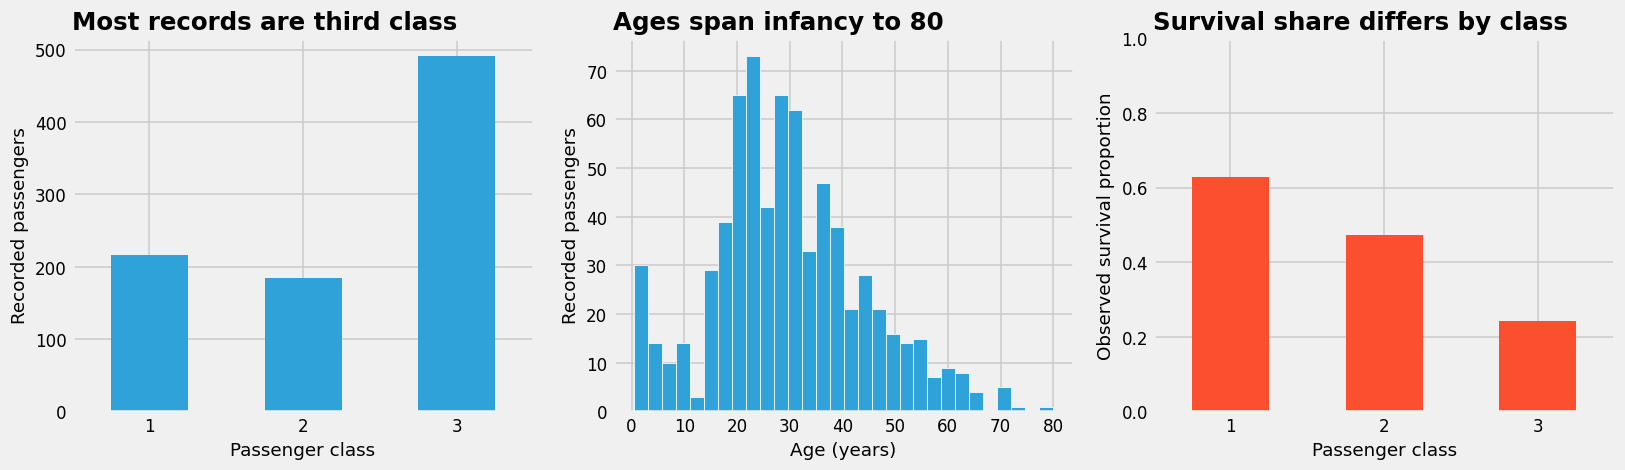

In [6]:
passenger_class_counts = titanic['Pclass'].value_counts().sort_index()
class_survival = titanic.groupby('Pclass')['Survived'].mean()
utils.plot_structure(passenger_class_counts, titanic['Age'].dropna(), class_survival)

<p>Takeaway: Choose summaries from variable meaning, not storage type alone. <code>Pclass</code> has a numeric dtype and an ordinal meaning. The association between class and survival describes these records. This table alone does not isolate a causal effect of class.</p>
<p>Back to the slides: How much detail should one record retain?</p>

<a id='section2'></a>
<h2>2. Granularity</h2>
<p>Why this section? You will follow bicycle detections through five-minute, hourly, daily, and monthly counts. Identify the detail lost at each step.</p>
<p>Question: Which questions lose their answers when you combine rows?</p>
<p>Keep the West and East sidewalk counts separate. First aggregate the same two hours. Then extend the observation period before calculating daily and monthly totals. Extending the period and aggregating records are separate operations.</p>

<a id='counter-events'></a>
<h3>1. Individual detections: when did a crossing occur?</h3>
<p>One row represents one detection. The file covers 08:00 to 10:00 on 3 October 2012, excluding 10:00. Each timestamp includes milliseconds. Each sidewalk label identifies a side of the bridge.</p>
<p>An event ID identifies a detection, not a person. One cyclist's repeated crossings produce separate events. These event records are the finest data available for this example. They do not contain the sensor's electrical signals. The opening data-source section describes the file's illustrative timestamps.</p>

In [7]:
counter_events = pd.read_csv('counter_events.csv', parse_dates=['detected_at'])
counter_events.head(10)

,event_id,detected_at,counter_id,sidewalk
0,evt-000001,2012-10-03 08:00:08.123,FREMONT,East
1,evt-000002,2012-10-03 08:00:09.644,FREMONT,East
2,evt-000003,2012-10-03 08:00:27.527,FREMONT,West
3,evt-000004,2012-10-03 08:00:29.010,FREMONT,East
4,evt-000005,2012-10-03 08:00:36.804,FREMONT,East
5,evt-000006,2012-10-03 08:00:38.765,FREMONT,West
6,evt-000007,2012-10-03 08:00:53.868,FREMONT,West
7,evt-000008,2012-10-03 08:00:54.006,FREMONT,East
8,evt-000009,2012-10-03 08:01:00.292,FREMONT,West
9,evt-000010,2012-10-03 08:01:03.009,FREMONT,East


<h3>2. Five-minute counts: when was the short burst?</h3>
<p>Question: After counting detections in five-minute intervals, will you still know the exact time of each crossing?</p>
<p><code>.size()</code> counts event rows for each interval and sidewalk. The 08:00 interval includes crossings from 08:00 up to 08:05, excluding 08:05.</p>
<p>This illustration contains every detection within the two-hour period. An empty interval therefore means zero detections. Without a complete recording, an empty interval would leave zero detections and missing data unresolved.</p>

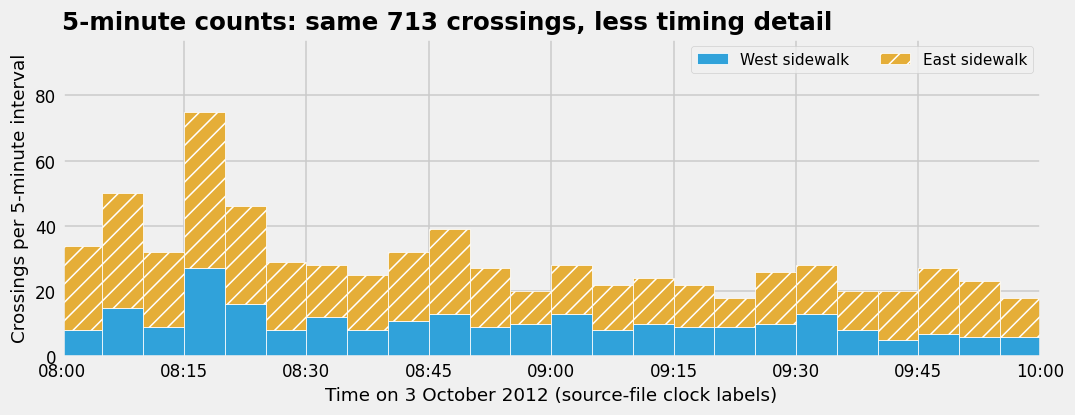

In [8]:
counter_five_minute = counter_events.groupby(
    [pd.Grouper(key='detected_at', freq='5min'), 'sidewalk']
).size().unstack('sidewalk', fill_value=0)
utils.plot_counter_counts(counter_five_minute, interval_minutes=5)

<p>The five-minute counts identify busy intervals on each sidewalk. They discard individual event IDs, precise timestamps, and the order and spacing of arrivals within each interval.</p>
<h3>3. Hourly counts: which hour was busier?</h3>
<p>Add the five-minute counts for each hour with <code>.sum()</code>. Using <code>.size()</code> would count rows rather than crossings. Keep the same two hours and separate sidewalk counts.</p>

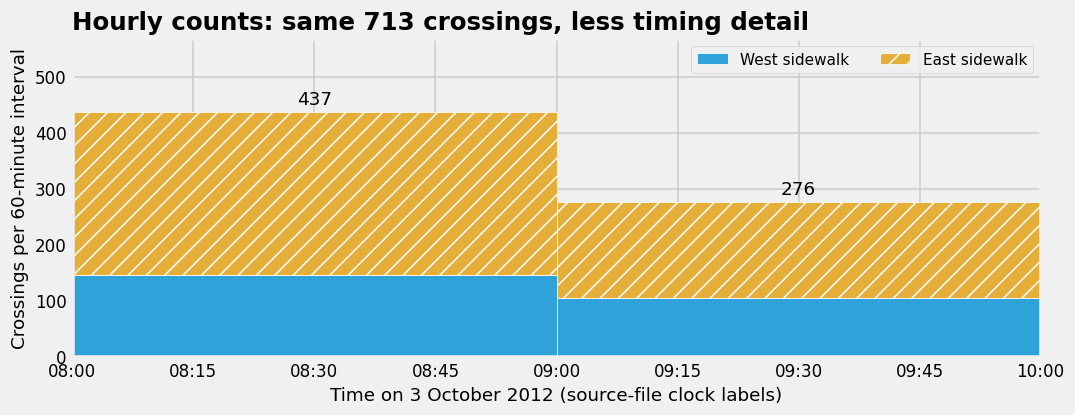

In [9]:
counter_hourly = counter_five_minute.resample('h').sum()
utils.plot_counter_counts(counter_hourly, interval_minutes=60)

<p>The first hour contains 437 crossings. The second contains 276. Both views describe the same 713 events. The hourly totals no longer identify the busiest five-minute interval. Each bar covers a longer period, so the vertical scale changes.</p>
<h3>Continue with the hourly record</h3>
<p>Load the hourly bicycle counts. Each row represents one hour, with separate counts for the West and East sidewalks. Use this longer record to explore daily and monthly totals.</p>

In [10]:
bikes = pd.read_csv('bike_traffic_data.csv')
bikes['Date'] = pd.to_datetime(bikes['Date'], format='%m/%d/%Y %I:%M:%S %p')
bikes = bikes.rename(columns={
    'Fremont Bridge West Sidewalk': 'West',
    'Fremont Bridge East Sidewalk': 'East',
}).set_index('Date').sort_index()
bikes.loc[counter_hourly.index]

,West,East
detected_at,,
2012-10-03 08:00:00,146.0,291.0
2012-10-03 09:00:00,104.0,172.0


<h3>Extend the observation period</h3>
<p>Two hours do not describe a full day or month. Use all 720 hourly records from November 2012. This file contains both sidewalk counts for all 30 labelled days.</p>
<p>The following hourly, daily, and monthly views describe the same 50,647 crossings. Only the interval length changes.</p>

In [11]:
november_hourly = bikes.loc['2012-11', ['West', 'East']]
november_hourly.head(3)

,West,East
Date,,
2012-11-01 00:00:00,3.0,4.0
2012-11-01 01:00:00,3.0,2.0
2012-11-01 02:00:00,1.0,1.0


<h3>4. Daily counts: which day was busier?</h3>
<p>Each row represents one day, with a separate count for each sidewalk. <code>min_count=24</code> requires 24 observed hourly counts before reporting a daily total.</p>
<p>A daily total discards the timing and size of peaks within the day. The total does not distinguish morning crossings from evening crossings.</p>

In [12]:
november_daily = november_hourly.resample('D').sum(min_count=24)
november_daily.head(3)

,West,East
Date,,
2012-11-01,1030.0,1061.0
2012-11-02,1133.0,1345.0
2012-11-03,439.0,513.0


<h3>5. Monthly counts: how much traffic in the month?</h3>
<p>Add the 30 daily counts to produce one November record. The monthly total retains volume by sidewalk. Daily differences and weekday patterns no longer appear.</p>
<p>Compare the three panels across the same dates. Their vertical scales differ because each point or bar covers a different duration.</p>

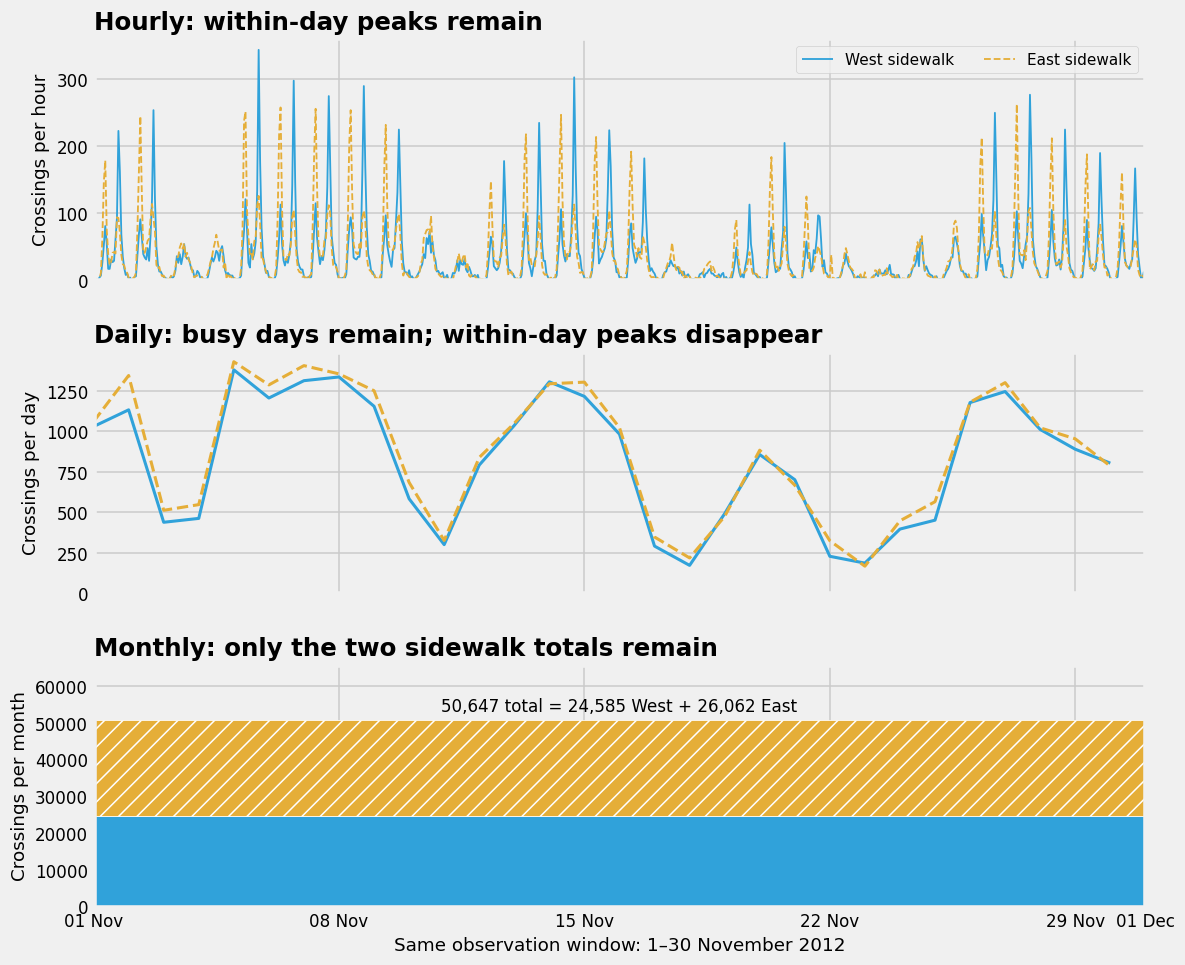

In [13]:
november_monthly = november_daily.resample('MS').sum(min_count=30)
utils.plot_bridge_month_progression(november_hourly, november_daily, november_monthly)

<table>
<thead><tr><th>Grain</th><th>Question still answerable</th><th>Detail lost at this step</th></tr></thead>
<tbody>
<tr><td>Individual detection</td><td>When did each crossing occur?</td><td>No aggregation yet</td></tr>
<tr><td>Five minutes</td><td>Which short interval was busiest?</td><td>Exact arrival times and event identity</td></tr>
<tr><td>Hour</td><td>Which hour was busiest?</td><td>Within-hour bursts</td></tr>
<tr><td>Day</td><td>Which day was busiest?</td><td>Within-day peaks</td></tr>
<tr><td>Month</td><td>How many crossings occurred during the month?</td><td>Day-to-day differences</td></tr>
</tbody>
</table>
<p>The West and East columns retain sidewalk detail. Adding those columns would remove the sidewalk distinction.</p>
<p>Takeaway: Aggregation removes detail. Choose an interval length suited to your question. Keep the observation period fixed when comparing interval lengths. Label partial-period totals as partial.</p>
<p>Back to the slides: Which patterns repeat over time?</p>

<a id='section3'></a>
<h2>3. Temporality</h2>
<p>Why this section? Use the full hourly record to compare patterns across hours, weekdays, and seasons. Check whether one average combines different patterns.</p>
<p>Question: Does the same daily pattern hold on weekdays and weekends?</p>
<p>Add West and East counts to calculate a bridge-wide total. This removes sidewalk detail. Calculate a total only when both measurements exist. Grouping by calendar labels compares recurring periods, rather than consecutive longer intervals.</p>

<p>Keep hourly records, add the two sidewalk counts, and extract calendar labels. Weekday numbers run from Monday = 0 to Sunday = 6. Use these labels to compare corresponding periods across days.</p>

In [14]:
bikes['Total'] = bikes[['West', 'East']].sum(axis=1, min_count=2)
bikes['hour'] = bikes.index.hour
bikes['dayofweek'] = bikes.index.dayofweek
bikes[['Total', 'hour', 'dayofweek']].head()

,Total,hour,dayofweek
Date,,,
2012-10-03 00:00:00,13.0,0,2
2012-10-03 01:00:00,10.0,1,2
2012-10-03 02:00:00,2.0,2,2
2012-10-03 03:00:00,5.0,3,2
2012-10-03 04:00:00,7.0,4,2


<p>Group by hour of day. Calculate the average count for each hour across the full record.</p>

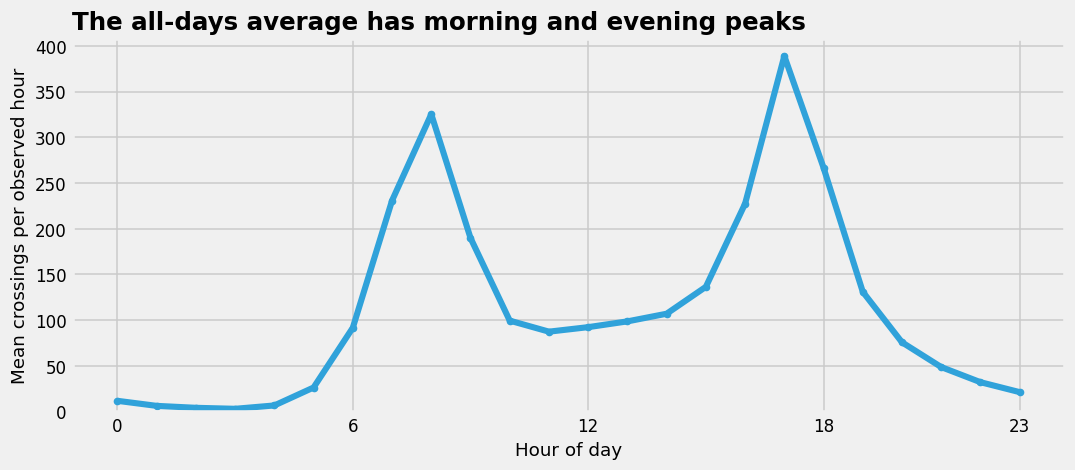

In [15]:
by_hour = bikes.groupby('hour')['Total'].mean()
utils.plot_hourly_profile(by_hour)

<a id='mfml-question-led-eda'></a>
<a id='weekday-weekend-comparison'></a>
<h3>Choose the next question</h3>
<p>The all-days average has morning and evening peaks.</p>
<p>Question: Do both weekdays and weekends show these peaks? What shape do you expect for weekends?</p>
<p>Keep the counter, hourly interval, and vertical scale fixed. Change only the weekday/weekend grouping. Each point averages observed hourly counts, not distinct cyclists. This comparison tests whether the pooled average conceals differences between weekdays and weekends.</p>

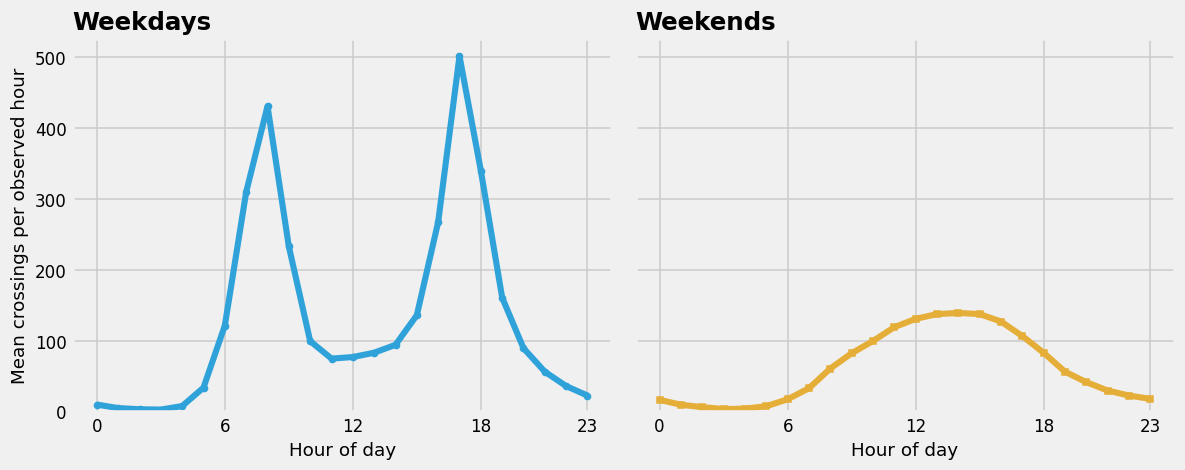

In [16]:
bikes['day_type'] = 'Weekday'
bikes.loc[bikes['dayofweek'] >= 5, 'day_type'] = 'Weekend'
weekday_weekend_profiles = bikes.groupby(['day_type', 'hour'])['Total'].mean()
utils.plot_weekday_weekend_profiles(weekday_weekend_profiles)

<p>The weekday profile has morning and evening peaks. The weekend profile peaks during the afternoon. The pooled average concealed this difference. The shared vertical scale also shows differences in the average counts.</p>
<p>Question: What would you investigate next?</p>
<p>Commuting offers one explanation for the weekday peaks, but the counter does not record journey purpose. Identify the evidence you would need before describing a particular crossing as a commute. These historical averages combine seasons and years. They do not forecast today's traffic.</p>

<p>Compare average hourly counts across the seven weekdays. Keep the denominator as observed hours.</p>

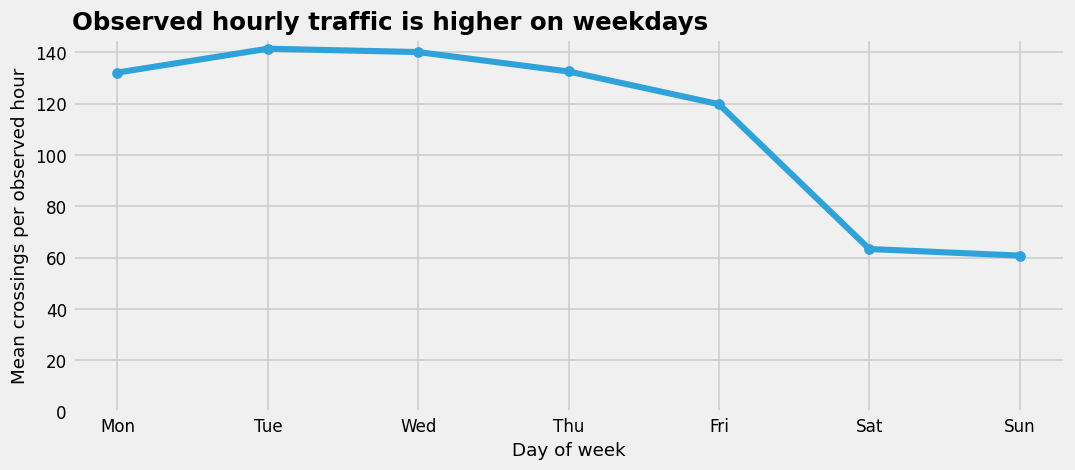

In [17]:
by_dow = bikes.groupby('dayofweek')['Total'].mean()
utils.plot_weekday_profile(by_dow)

<p>Compare calendar months across the historical record. Month lengths differ, so use mean daily traffic rather than monthly sums. Require all 24 hourly totals for each labelled day. Each monthly average includes only complete recorded days. This calculation does not estimate traffic for omitted days.</p>

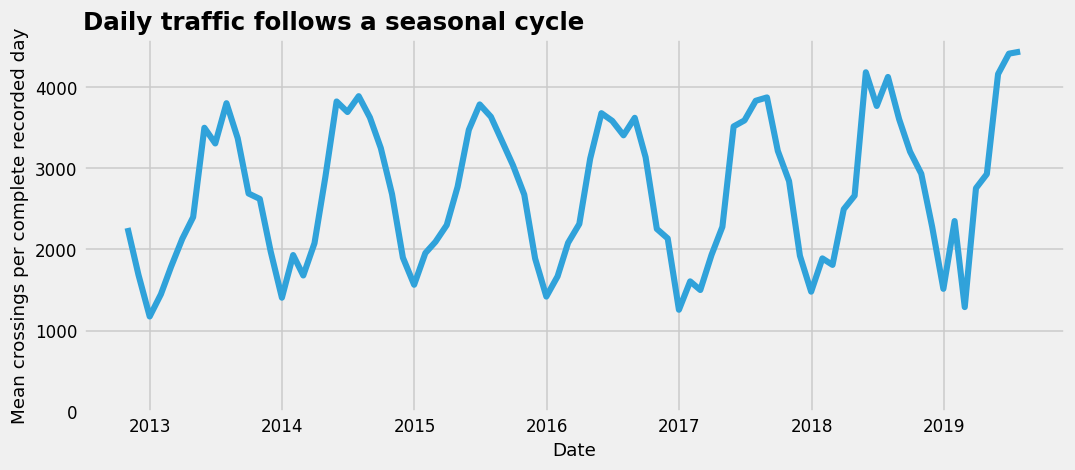

In [18]:
daily = bikes['Total'].resample('D').sum(min_count=24)
monthly_daily_mean = daily.resample('ME').mean()
utils.plot_seasonal_profile(monthly_daily_mean)

<p>Takeaway: This counter records daily, weekly, and seasonal patterns. The weekday peaks fit a commuting explanation but do not establish rider purpose. Check the denominator and missing measurements before interpreting each temporal summary.</p>
<p>Back to the slides: Do the recorded values mean what you expect?</p>

<a id='section4'></a>
<h2>4. Faithfulness</h2>
<p>Why this section? Some stored numbers represent missing data rather than measurements. Check the Mauna Loa CO₂ file's missing-value codes. Compare dropping, marking, and filling those entries.</p>
<p>Question: Does each recorded value mean what you expect?</p>
<p>The file header identifies <code>-99.99</code> as a missing monthly reading. Use this definition to interpret the value.</p>

<p>The file starts with comment lines marked by <code>#</code>. Spaces separate the data fields. Read the file and assign column names.</p>

In [19]:
co2 = pd.read_csv(
    'co2_mm_mlo.txt',
    comment='#',
    sep=r'\s+',
    header=None,
    names=['Yr', 'Mo', 'DecDate', 'Avg', 'Int', 'Trend', 'Days'],
)
co2['Period'] = pd.PeriodIndex.from_fields(
    year=co2['Yr'], month=co2['Mo'], freq='M'
)
co2.head()

,Yr,Mo,DecDate,Avg,Int,Trend,Days,Period
0,1958,3,1958.208,315.71,315.71,314.62,-1,1958-03
1,1958,4,1958.292,317.45,317.45,315.29,-1,1958-04
2,1958,5,1958.375,317.50,317.50,314.71,-1,1958-05
3,1958,6,1958.458,-99.99,317.10,314.85,-1,1958-06
4,1958,7,1958.542,315.86,315.86,314.98,-1,1958-07


<p>Plot the raw <code>Avg</code> column before applying the documented missing-value rule.</p>

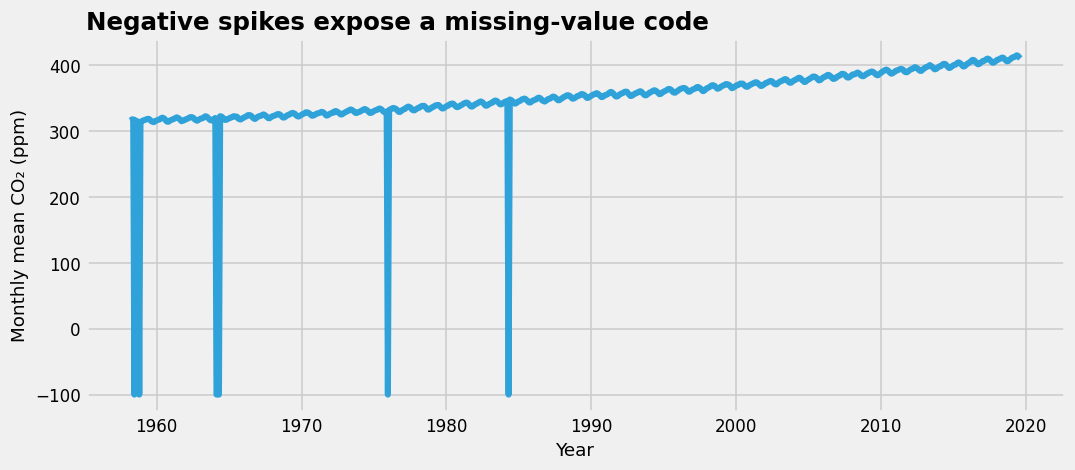

In [20]:
utils.plot_co2_raw(co2)

<p>The downward spikes come from the <code>-99.99</code> missing-value code. They do not represent measured CO₂ concentrations. Filter negative values to locate these entries.</p>

In [21]:
co2[co2['Avg'] < 0]

,Yr,Mo,DecDate,Avg,Int,Trend,Days,Period
3,1958,6,1958.458,-99.99,317.10,314.85,-1,1958-06
7,1958,10,1958.792,-99.99,312.66,315.61,-1,1958-10
71,1964,2,1964.125,-99.99,320.07,319.61,-1,1964-02
72,1964,3,1964.208,-99.99,320.73,319.55,-1,1964-03
73,1964,4,1964.292,-99.99,321.77,319.48,-1,1964-04
213,1975,12,1975.958,-99.99,330.59,331.60,0,1975-12
313,1984,4,1984.292,-99.99,346.84,344.27,2,1984-04


<h3>Check the other columns</h3>
<p>The header defines a second missing-value code. <code>Days = -1</code> means the number of daily means contributing to a monthly record is unavailable.</p>
<p>First check the monthly sequence. Each year-month pair should appear once within the file's date range.</p>

In [22]:
expected_periods = pd.period_range(
    co2['Period'].min(), co2['Period'].max(), freq='M'
)
missing_periods = expected_periods.difference(co2['Period'])

print('Recorded months:', len(co2))
print('Expected months:', len(expected_periods))
print('Missing months:', len(missing_periods))
print('Repeated year-month pairs:', co2['Period'].duplicated().sum())

Recorded months: 738
Expected months: 738
Missing months: 0
Repeated year-month pairs: 0


<p>The recorded year-month pairs match the expected sequence without duplicates. Counting month names alone would miss a missing January in one year paired with a duplicate January in another. A complete record sequence still permits missing measurements within rows.</p>

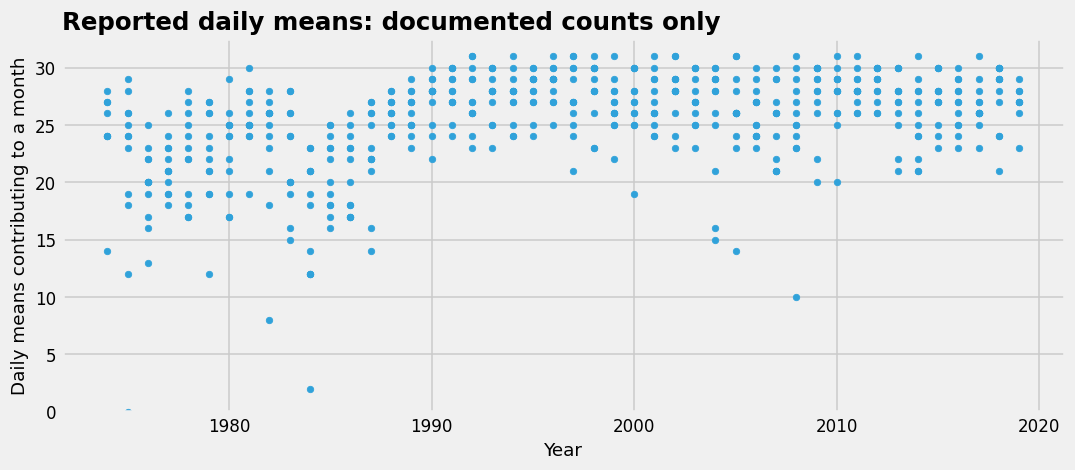

In [23]:
known_day_counts = co2.loc[co2['Days'] != -1]
utils.plot_co2_day_counts(known_day_counts)

<p>The header defines <code>Days = -1</code> as an unavailable count of daily means. The code does not describe negative counts or establish low measurement coverage.</p>
<p>The file contains 194 such records from 1958 to 1974. Of these, 189 contain an observed monthly average. Omit the unknown day counts from the plot. This field supplies no measured day count for those months.</p>
<p>Missing metadata differs from a missing monthly average. Return to <code>Avg</code> and its <code>-99.99</code> code.</p>

<h3>Three treatments for missing values</h3>
<p>Seven rows contain <code>-99.99</code>. Compare three treatments.</p>
<ol>
<li>Drop the affected rows.</li>
<li>Replace the code with <code>NaN</code> to mark missing measurements.</li>
<li>Use the file's interpolated <code>Int</code> values as estimates.</li>
</ol>

In [24]:
# 1. Drop records whose monthly average is a sentinel.
missing_avg = co2['Avg'] == -99.99
co2_drop = co2.loc[~missing_avg].copy()
print('rows dropped:', missing_avg.sum())
co2_drop.head()

rows dropped: 7


,Yr,Mo,DecDate,Avg,Int,Trend,Days,Period
0,1958,3,1958.208,315.71,315.71,314.62,-1,1958-03
1,1958,4,1958.292,317.45,317.45,315.29,-1,1958-04
2,1958,5,1958.375,317.50,317.50,314.71,-1,1958-05
4,1958,7,1958.542,315.86,315.86,314.98,-1,1958-07
5,1958,8,1958.625,314.93,314.93,315.94,-1,1958-08


<p><code>replace()</code> changes the documented code <code>-99.99</code> to <code>NaN</code>. Limit the replacement to <code>Avg</code>.</p>

In [25]:
# 2. Replace the documented sentinel with NaN.
co2_na = co2.copy()
co2_na['Avg'] = co2_na['Avg'].replace(-99.99, np.nan)
print('Missing monthly averages:', co2_na['Avg'].isna().sum())
co2_na.loc[missing_avg, ['Period', 'Avg', 'Int']].head()

Missing monthly averages: 7


,Period,Avg,Int
3,1958-06,NaN,317.10
7,1958-10,NaN,312.66
71,1964-02,NaN,320.07
72,1964-03,NaN,320.73
73,1964-04,NaN,321.77


<p><code>fillna()</code> fills missing averages from the corresponding <code>Int</code> values. Recorded averages stay unchanged.</p>

In [26]:
# 3. Fill missing averages with NOAA's interpolated values.
co2_impute = co2_na.copy()
co2_impute['Avg'] = co2_impute['Avg'].fillna(co2_impute['Int'])
co2_impute.loc[missing_avg, ['Period', 'Avg', 'Int']].head()

,Period,Avg,Int
3,1958-06,317.10,317.10
7,1958-10,312.66,312.66
71,1964-02,320.07,320.07
72,1964-03,320.73,320.73
73,1964-04,321.77,321.77


<p>Compare the first years of each plot. Dropping rows connects across missing months. Keeping <code>NaN</code> leaves gaps. Interpolation adds estimated values. Each treatment makes a different continuity assumption.</p>

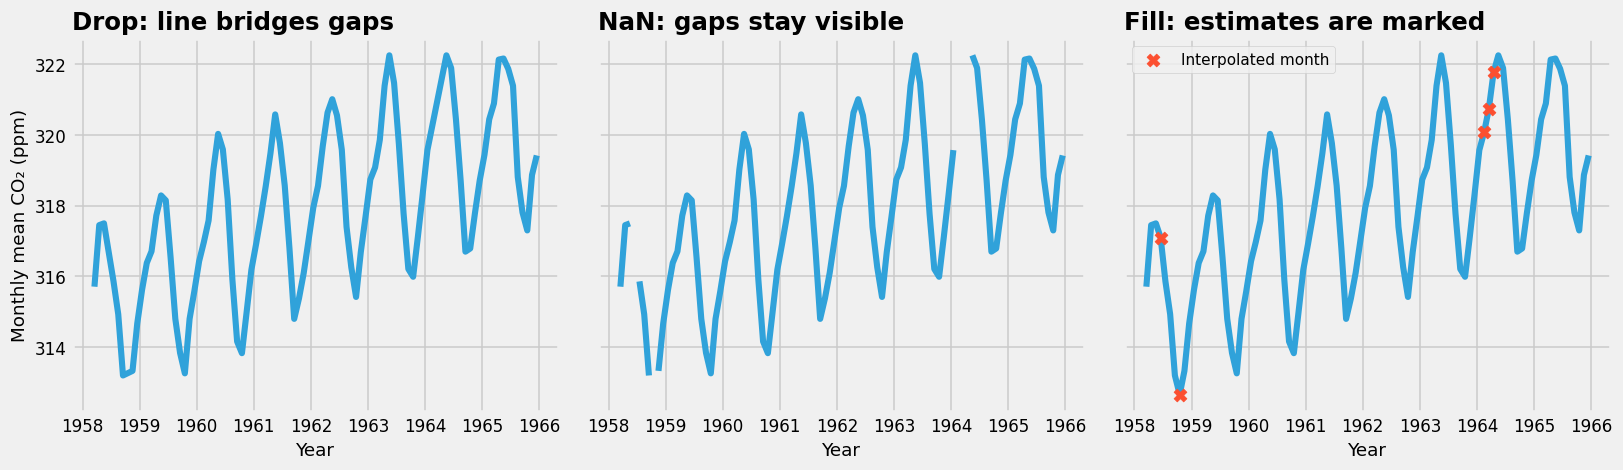

In [27]:
utils.plot_co2_treatments(co2_drop, co2_na, co2_impute, missing_avg)

<p>Takeaway: The year-month sequence is complete, but seven monthly averages are missing. The file marks them with <code>-99.99</code>. Choose a treatment suited to the analysis, preserve observed values, and document your choice.</p>
<p>Back to the slides: Which people, places, and periods does the dataset omit?</p>

<a id='section5'></a>
<h2>5. Scope</h2>
<p>Why this section? The slides asked whether a dataset covers the intended population and period. Compare the scope of our three datasets, then audit the bridge file's timestamps and measurements.</p>
<p>Question: Does a complete sequence of hourly records establish complete measurements?</p>
<table>
<thead><tr><th>Dataset</th><th>Observed unit</th><th>Coverage limit</th></tr></thead>
<tbody>
<tr><td>Titanic</td><td>One recorded passenger</td><td>One ship and an incomplete historical record</td></tr>
<tr><td>Fremont Bridge</td><td>One counter-hour</td><td>Two sidewalks on one Seattle bridge</td></tr>
<tr><td>Mauna Loa CO₂</td><td>One station-month</td><td>One location and its documented measurement process</td></tr>
</tbody>
</table>
<p>Define the intended population before checking coverage. A complete extract from one source does not establish coverage of a wider population.</p>

<a id='mfml-observed-sample'></a>
<a id='bridge-observation-scope'></a>
<h3>Claims from one bridge counter</h3>
<p>The Fremont counter records crossings at one site during a specific period. A citywide analysis needs evidence beyond this site.</p>
<figure style='margin: 1em 0;'>
<img src='images/bridge_counter_scope.png' alt='One monitored bridge crossing contrasted with an unmeasured neighbourhood street and downtown bike lane.' style='width: 100%; max-width: 1100px; height: auto;'/>
<figcaption>A bridge crossing does not identify a cyclist's origin, destination, or route. Bicycle counts on either street require measurements from those locations.</figcaption>
</figure>
<p>Question: Which claims does this dataset support?</p>
<ol>
<li>This crossing has different weekday and weekend profiles in the recorded data.</li>
<li>Every timestamped row contains a measured bicycle count.</li>
<li>The same profile describes cycling across Seattle.</li>
</ol>
<p>Check the recorded measurements and geographic coverage. Identify claims requiring another source. Additional rows from this counter do not measure other routes.</p>

<p>Build the expected hourly sequence and check for missing or repeated timestamps. Then use <code>info()</code> to compare the row count with each column's nonmissing count. <code>Total</code> is missing when either sidewalk count is missing.</p>
<p>Use the hourly clock labels supplied by the file. This check does not resolve timezone or daylight-saving conventions.</p>

In [28]:
expected_hours = pd.date_range(bikes.index.min(), bikes.index.max(), freq='h')
missing_hours = expected_hours.difference(bikes.index)

print('Expected hourly timestamps:', len(expected_hours))
print('Missing timestamps:', len(missing_hours))
print('Repeated timestamps:', bikes.index.duplicated().sum())
bikes[['West', 'East', 'Total']].info()

Expected hourly timestamps: 59832
Missing timestamps: 0
Repeated timestamps: 0
<class 'pandas.DataFrame'>
DatetimeIndex: 59832 entries, 2012-10-03 00:00:00 to 2019-07-31 23:00:00
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   West    59823 non-null  float64
 1   East    59823 non-null  float64
 2   Total   59823 non-null  float64
dtypes: float64(3)
memory usage: 3.8 MB


<h3>Check the claims</h3>
<ol>
<li>The profiles describe observed counts at this crossing during the file's date range.</li>
<li>All 59,832 expected timestamp labels appear once. Only 59,823 rows contain both measurements. Nine rows have missing counts.</li>
<li>The counter does not observe other routes or people who avoid this bridge. Citywide claims require additional evidence.</li>
</ol>
<p>Takeaway: Check the intended population, recorded period, and measured values separately. Complete timestamps do not guarantee complete measurements.</p>
<p>Back to the slides: Continue with Spatiality. Next, map California home values and compare nearby locations.</p>

<a id='section6'></a>
<h2>6. Spatiality</h2>
<p>Why this section? You will test whether nearby places have similar home values. A distribution alone does not show where high and low values occur.</p>
<p>Question: Do home values form geographic clusters, or do high and low values mix throughout California?</p>
<p>The California housing dataset contains 20,640 census block groups from 1990. Each row describes a small area, not an individual house. We will use its coordinates and reported median home value.</p>
<h3>Map the observations, then shuffle the values</h3>
<p>Several block groups share rounded coordinates. Average their median values at each coordinate before plotting. Each dot then represents one recorded location. Both maps use identical coordinates, values, and colour scales. Only the assignment of values to locations changes.</p>

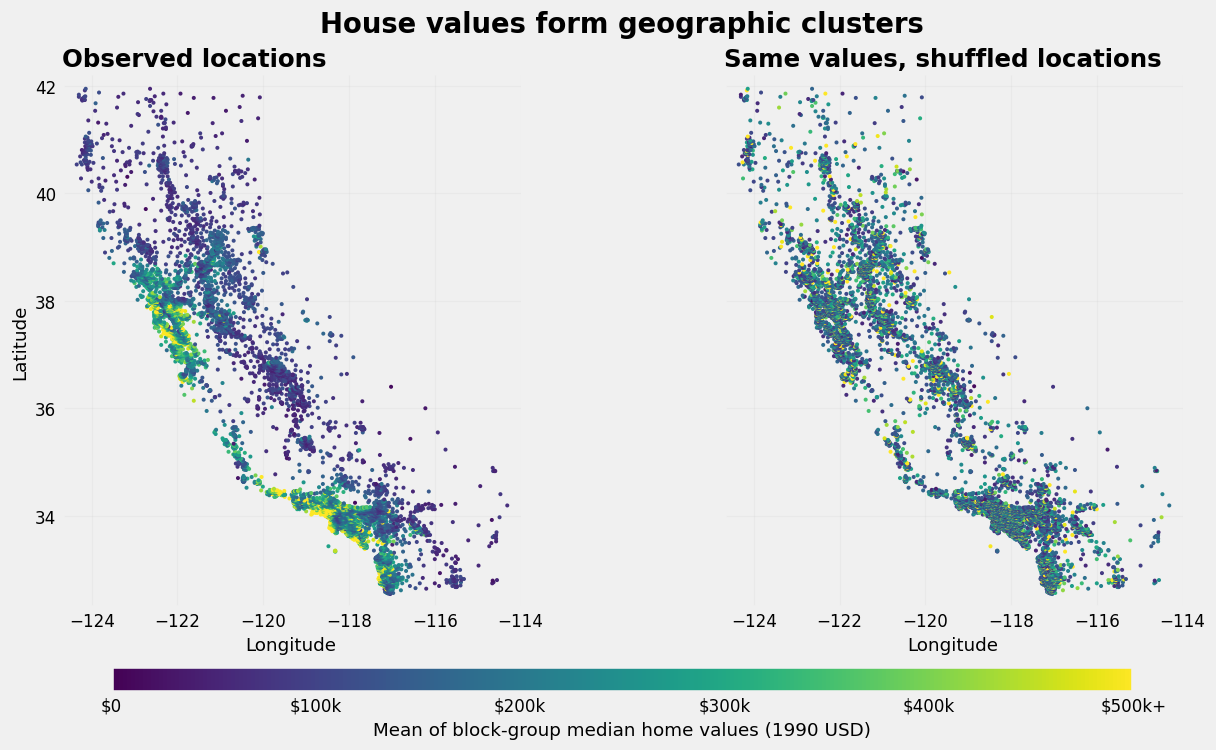

In [29]:
housing = pd.read_csv(
    'california_housing.csv', header=None, usecols=[0, 1, 8],
    names=['longitude', 'latitude', 'median_house_value'],
)
housing_locations = housing.groupby(
    ['latitude', 'longitude'], as_index=False
)['median_house_value'].mean()
utils.plot_housing_maps(housing_locations, random_state=RANDOM_STATE)

<p>Nearby dots often share similar colours in the observed map. Shuffling breaks up those clusters without changing the distribution of values. The geographic arrangement contains information beyond the overall histogram.</p>
<p>These are historical values in 1990 US dollars. The highest colour includes the file's upper recorded value of $500,001. Unplotted areas have no observations in this extract.</p>
<h3>Compare each location with its nearest neighbour</h3>
<p>Question: How much do nearby values differ before and after shuffling?</p>
<p>Pair each location with its nearest distinct coordinate using distance on a sphere. Calculate the absolute difference in home value. Repeat with the same location pairs after shuffling values once. Each location contributes one comparison.</p>

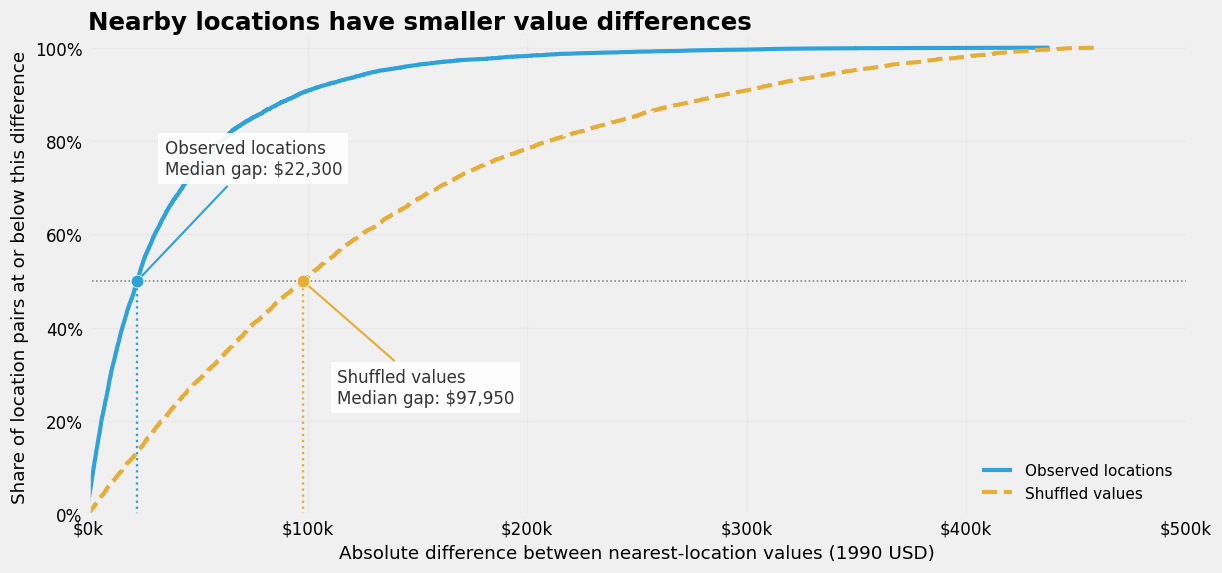

In [30]:
neighbour_pairs = utils.nearest_location_pairs(
    housing_locations, random_state=RANDOM_STATE
)
utils.plot_neighbour_differences(neighbour_pairs)

<p>Read across from 50% on the vertical axis. Half of the observed pairs differ by $22,300 or less. The shuffled comparison reaches 50% at $97,950. Nearby locations have more similar values than this shuffled arrangement.</p>
<p>This pattern illustrates positive spatial autocorrelation. Shared housing, access, and local conditions are possible explanations. This comparison does not isolate a cause or provide a formal significance test.</p>
<p>Takeaway: Map observations before treating geographic rows as unrelated. For a model intended for a new area, assess performance on held-out locations rather than relying only on a random row split.</p>
<p>Back to the slides: Continue with Domain Context. Next, use measurement definitions to judge unusual values.</p>

<a id='section7'></a>
<h2>7. Domain Context</h2>
<p>Why this section? You will decide whether negative earthquake magnitudes need cleaning. A rule based on the sign alone would remove valid observations.</p>
<p>Question: Earlier, negative CO₂ values marked missing measurements. Should negative earthquake magnitudes also go?</p>
<p>The USGS catalogue extract covers January 2025 within a California-Nevada study window, 32° to 37° N and 121° to 114° W. One row represents a recorded earthquake. Select reviewed events with local magnitude, <code>ml</code>, so the example uses one magnitude definition.</p>

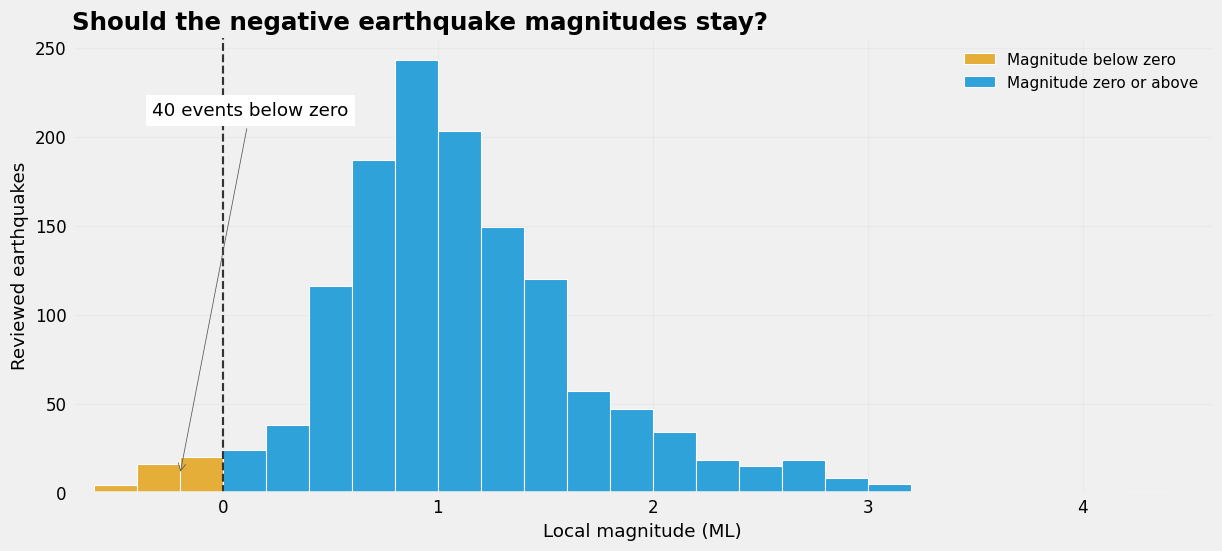

In [31]:
earthquake_catalogue = pd.read_csv(
    'usgs_california_nevada_2025_01.csv', parse_dates=['time']
)
earthquakes = earthquake_catalogue.loc[
    (earthquake_catalogue['magType'] == 'ml')
    & (earthquake_catalogue['status'] == 'reviewed')
].copy()
utils.plot_earthquake_magnitudes(earthquakes)

<p>The selection contains 1,323 reviewed earthquakes. Forty have magnitudes below zero. A negative sign alone does not establish a recording error.</p>
<h3>The measurement definition changes the cleaning decision</h3>
<p>Local magnitude uses a logarithmic amplitude scale. In the simplified relationship <code>M<sub>L</sub> = log₁₀(A/A₀)</code>, A is signal amplitude and A₀ is the reference for the source distance. An amplitude one tenth of the reference gives magnitude −1. The amplitude stays positive.</p>
<p>The <a href='https://www.usgs.gov/faqs/how-can-earthquake-have-a-negative-magnitude'>USGS explanation of negative magnitudes</a> describes this scale. The diagram below illustrates the relationship. The catalogue does not supply the signal amplitudes used in the diagram.</p>
<p>Compare the full selection with a copy restricted to nonnegative magnitudes. Keep the original observations unchanged.</p>

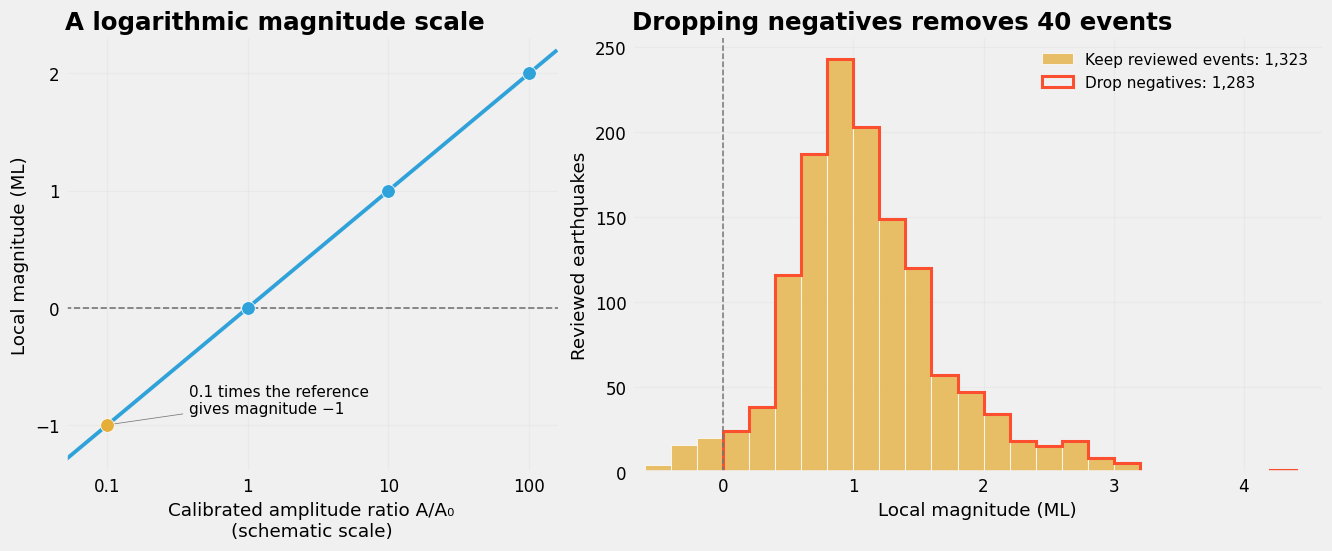

In [32]:
nonnegative_only = earthquakes.loc[earthquakes['mag'] >= 0]
utils.plot_magnitude_context(earthquakes, nonnegative_only)

<p>The filter removes 40 reviewed events, about 3% of this selection. The smallest recorded earthquakes disappear from the left side of the distribution. A visually tidier range would give an incomplete account of the catalogue.</p>
<p>The negative CO₂ code required missing-value handling. Negative local earthquake magnitude has a physical meaning. The correct decision depends on the variable's definition.</p>
<p>Takeaway: Read the measurement definition before changing unusual values. Keep these negative magnitudes. Recording thresholds also affect which small earthquakes enter the catalogue, so this histogram does not count every earthquake in the region.</p>
<p>Back to the slides: Continue with documenting the analysis. Record the measurement definitions and the reasons for each cleaning decision.</p>

<h2>Lecture summary</h2>
<p>Check variable meaning, row granularity, time patterns, missing-value codes, and population coverage before fitting a model. Map geographic observations to inspect spatial dependence. Use measurement definitions before changing unusual values.</p>
<p>A complete timestamp sequence does not guarantee complete measurements. Nearby records need not supply independent geographic evidence. A negative sign has different meanings for a CO₂ missing-value code and a logarithmic earthquake magnitude.</p>
<p>Back to the slides: Document the supported claims and the reasons for cleaning decisions.</p>